### 0. Load librairies and data

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn import datasets
from nilearn.glm import threshold_stats_img
from nilearn.glm.first_level import FirstLevelModel
from nilearn.glm.first_level import make_first_level_design_matrix
from nilearn.image import mean_img, load_img, resample_to_img, math_img
from nilearn.plotting import plot_stat_map
from nilearn.plotting import plot_design_matrix
from nilearn.reporting import get_clusters_table


data_dir = Path("../data") 
output_dir = Path("../output")

func_path = (
    data_dir / "fMRI" / "tfMRI_LANGUAGE_LR"
    / "tfMRI_LANGUAGE_LR.nii.gz"
)
events_path = (
    data_dir / "fMRI" / "tfMRI_LANGUAGE_LR" / "tfMRI_LANGUAGE_LR_task_onsets.csv"
)

preprocessed_path = (
    output_dir / "tfMRI_LANGUAGE_LR_trim_moco_smoothed-6mm.nii.gz"
)


In [ ]:
# Shared plotting settings
fdr_rate = 0.05
cluster_size = 10                    # voxels (10 x 8 mm^3 = 80 mm^3 at 2 mm), as in the lab
cuts = [-26, -6, 6, 16, 30, 46]      # same axial slices (MNI z, mm) for every map
background = datasets.load_mni152_template(resolution=2)   # MNI background instead of mean EPI

In [3]:
events_raw = pd.read_csv(events_path)

print("Columns:", events_raw.columns.tolist())
display(events_raw.head(15))
print(events_raw.dtypes)

Columns: ['onset', 'duration', 'trial_type']


,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


onset         float64
duration      float64
trial_type        str
dtype: object


In [4]:
# Keep only math and story as events
events = (
    events_raw.loc[
        events_raw["trial_type"].isin(["story", "math"]),
        ["onset", "duration", "trial_type"]
    ]
    .sort_values("onset")
    .reset_index(drop=True)
)

display(events)

,onset,duration,trial_type
0,0.241,28.270,story
1,30.095,12.241,math
2,42.570,12.312,math
3,56.524,27.147,story
4,85.206,12.667,math
5,98.120,12.542,math
6,112.274,26.070,story
7,139.930,11.844,math
8,152.045,12.528,math
9,164.853,9.838,math


The first 10 volumes were removed, discarding the scans before steady state is reached. This is consistent with the preprocessing.

In [ ]:

img = nib.load(func_path)

TR = float(img.header.get_zooms()[3])
n_scans = img.shape[3]

# Remove 10 first volumes
n_dropped = 10

# Create acquisition times
frame_times = (np.arange(n_scans - n_dropped) + n_dropped) * TR 

# Motion parameters (6 columns: 3 rotations, 3 translations)
motion = np.loadtxt(output_dir / "tfMRI_LANGUAGE_LR_trim_moco.par") 
motion_names = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]

In [6]:
print("TR:", TR)

TR: 0.7200000286102295


### a. Build experimental design matrix 

TODO Add explanation of the columns

2 × (306 × 0.72 s) × 0.01 Hz ≈ 4.4, which rounds down to 4 cosine regressors.

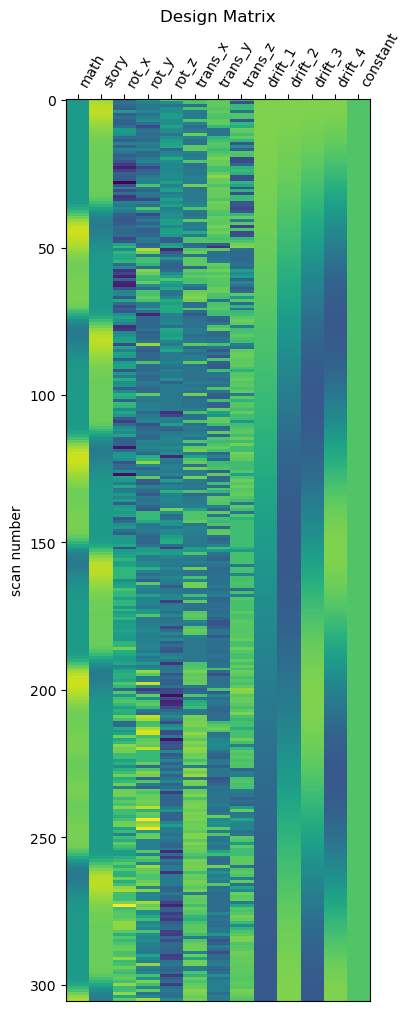

Matrix shape: (306, 13)
Columns: ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


In [7]:
# Create design matrix
# Cutoff frequency of 0.01 Hz (100sec) gives 4 drift regressors  
design_matrix = make_first_level_design_matrix(
    frame_times=frame_times,
    events=events,
    hrf_model="glover",
    drift_model="cosine",
    high_pass=0.01,
    add_regs=motion,
    add_reg_names=motion_names,
)

plot_design_matrix(design_matrix)
plt.title("Design Matrix")
plt.show()

print("Matrix shape:", design_matrix.shape)
print("Columns:", design_matrix.columns.tolist())

### b. Compute and plot correlation matrix between regressors of the design matrix

TODO Add explanations

,math,story,rot_x,rot_y,rot_z,trans_x,trans_y,trans_z,drift_1,drift_2,drift_3,drift_4
math,1.00,-0.95,-0.08,0.23,-0.04,0.22,0.13,-0.06,-0.04,-0.16,0.16,-0.31
story,-0.95,1.00,0.07,-0.21,0.04,-0.21,-0.11,0.03,0.09,0.19,-0.10,0.32
rot_x,-0.08,0.07,1.00,0.36,-0.46,0.34,-0.75,0.19,-0.75,0.02,-0.01,-0.02
rot_y,0.23,-0.21,0.36,1.00,-0.33,0.74,-0.08,-0.20,-0.44,0.10,0.13,-0.27
rot_z,-0.04,0.04,-0.46,-0.33,1.00,-0.31,0.33,-0.21,0.54,0.01,-0.01,0.08
trans_x,0.22,-0.21,0.34,0.74,-0.31,1.00,-0.09,-0.12,-0.49,0.21,0.09,-0.13
trans_y,0.13,-0.11,-0.75,-0.08,0.33,-0.09,1.00,-0.44,0.53,0.22,0.06,0.03
trans_z,-0.06,0.03,0.19,-0.20,-0.21,-0.12,-0.44,1.00,-0.28,-0.27,-0.17,0.14
drift_1,-0.04,0.09,-0.75,-0.44,0.54,-0.49,0.53,-0.28,1.00,0.00,-0.00,-0.00
drift_2,-0.16,0.19,0.02,0.10,0.01,0.21,0.22,-0.27,0.00,1.00,-0.00,-0.00


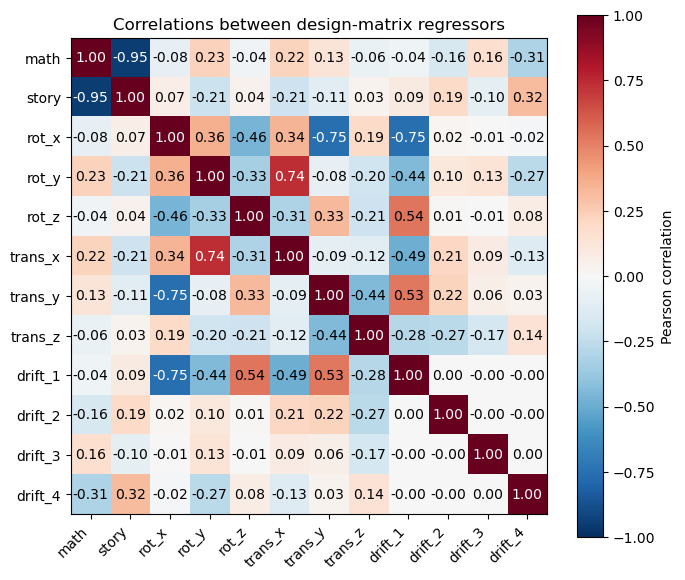

In [8]:
# Exclude the constant (its correlation is undefined)
regressors = design_matrix.drop(columns="constant")

# Compute correlations between columns
correlation = regressors.corr()

# Display the numerical values
display(correlation.round(2))

# Plot the correlation matrix
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)

names = correlation.columns
ax.set_xticks(range(len(names)), labels=names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), labels=names)

for i in range(len(names)):
    for j in range(len(names)):
        ax.text(
            j, i, f"{correlation.iloc[i, j]:.2f}",
            ha="center", va="center",
            color="white" if abs(correlation.iloc[i, j]) > 0.6 else "black"
        )

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlations between design-matrix regressors")
plt.tight_layout()
plt.show()


### c. Run GLM

We performed a first-level GLM on the single-subject run. A second-level analysis would be used to combine results across subjects and draw population-level conclusions.

In [9]:
#Check that the image and matrix have the same number of timepoints
preprocessed_img = nib.load(preprocessed_path)

print("fMRI volumes:", preprocessed_img.shape[3])
print("Design matrix rows:", len(design_matrix))

assert preprocessed_img.shape[3] == len(design_matrix)

fMRI volumes: 306
Design matrix rows: 306


In [10]:
# Fitting the GLM
# Single-subject, run-level analysis
# noise_model accounts for the fact that noise in neighbouring timepoints can be correlated
# No smoothing as preprocessing has handled it
glm = FirstLevelModel(
    noise_model="ar1",
    smoothing_fwhm=None,
)

# Find weights for each column, at every voxel
glm.fit(
    preprocessed_img,
    design_matrices=design_matrix,
)

FirstLevelModel()

In [11]:
# Compute contrasts
# Test whether the math weight differ from zero
# H0 : beta_math = 0
z_math = glm.compute_contrast(
    "math", stat_type="t", output_type="z_score"
)

# Test whether the story weight differ from zero
# H0 : beta_story = 0
z_story = glm.compute_contrast(
    "story", stat_type="t", output_type="z_score"
)

Math: FDR threshold |z| > 4.00, 169 voxels are kept
Story: FDR threshold |z| > 3.77, 515 voxels are kept


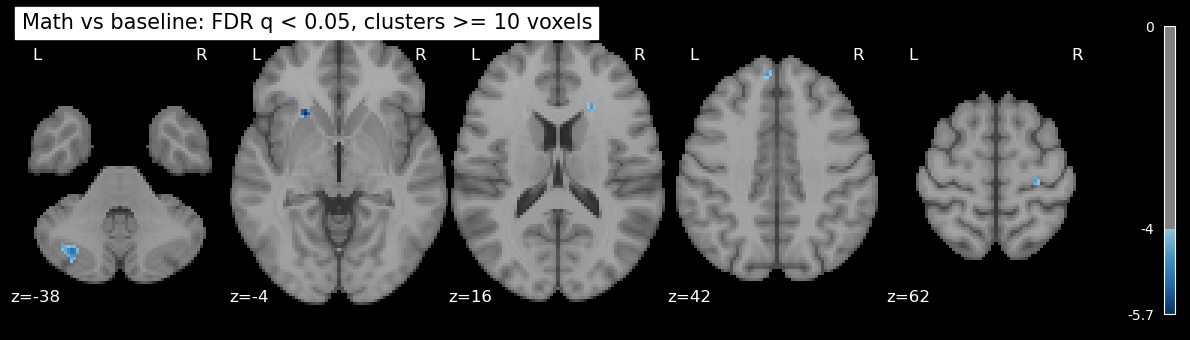

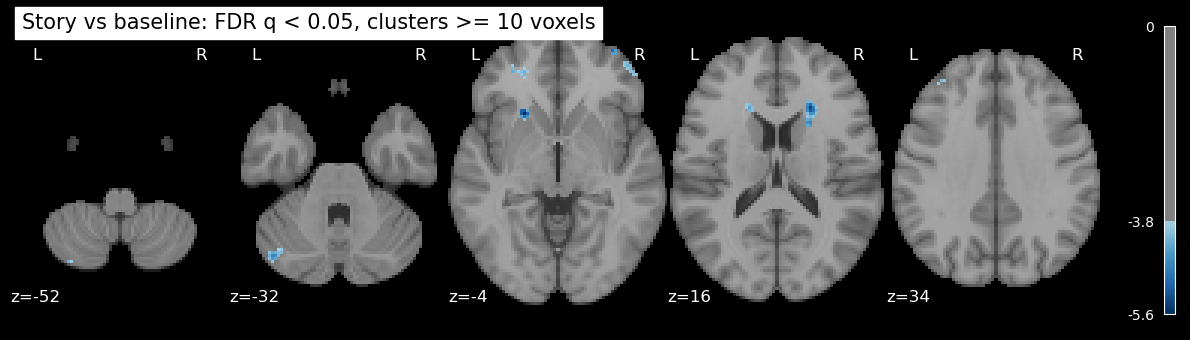

In [18]:
# Display maps
thresholded = {}

for name, z_map in [("Math", z_math), ("Story", z_story)]:
    # Apply FDR correction and thresholding
    clean_map, threshold = threshold_stats_img(z_map, alpha=fdr_rate, height_control='fdr', cluster_threshold=cluster_size)

    # Display number of voxels kept after thresholding
    thresholded[name] = (clean_map, threshold)
    n_sig = int((np.abs(clean_map.get_fdata()) > 0).sum())
    print(f"{name}: FDR threshold |z| > {threshold:.2f}, {n_sig} voxels are kept")

    # Plot results
    plot_stat_map(
        clean_map,
        bg_img=background,
        display_mode="z",
        cut_coords=5,
        threshold=threshold,
        title=f"{name} vs baseline: FDR q < {fdr_rate}, clusters >= {cluster_size} voxels",
    )

plt.show()

We included an unthresholded difference to see the effet of the FDR.

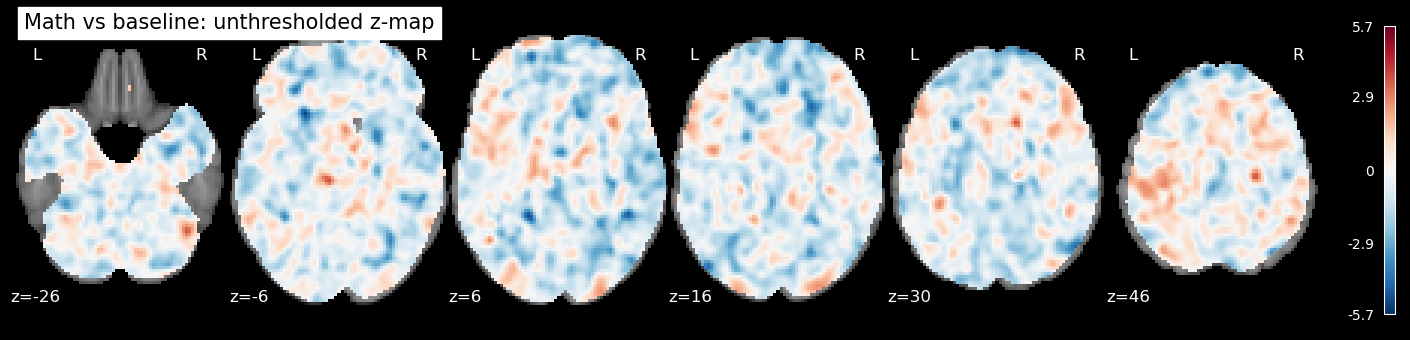

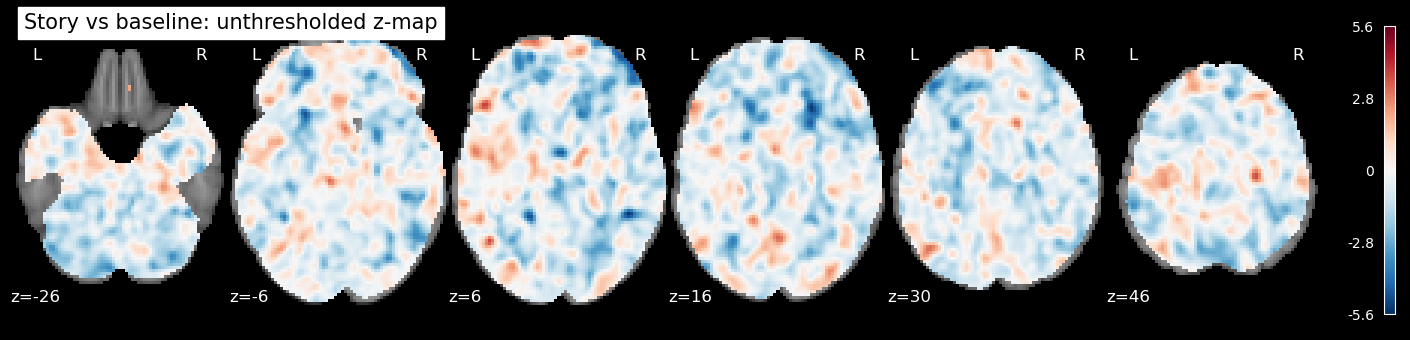

In [ ]:
# Unthresholded versions (useful for the appendix: shows the pattern even if not significant)
for name, z_map in [("Math", z_math), ("Story", z_story)]:
    plot_stat_map(z_map, bg_img=background, display_mode="z", cut_coords=cuts,
                  title=f"{name} vs baseline: unthresholded z-map")
plt.show()

### d. Story vs math contrast and activation map

In [13]:
# Test whether the story weight differ from the math weight
# H0 : beta_story - beta_math = 0
z_story_minus_math = glm.compute_contrast(
    "story - math",
    stat_type="t",
    output_type="z_score"
)

Story - Math: FDR threshold |z| > 2.41
Voxels story > math: 31473
Voxels math > story: 32517
math       -1
story       1
rot_x       0
rot_y       0
rot_z       0
trans_x     0
trans_y     0
trans_z     0
drift_1     0
drift_2     0
drift_3     0
drift_4     0
constant    0


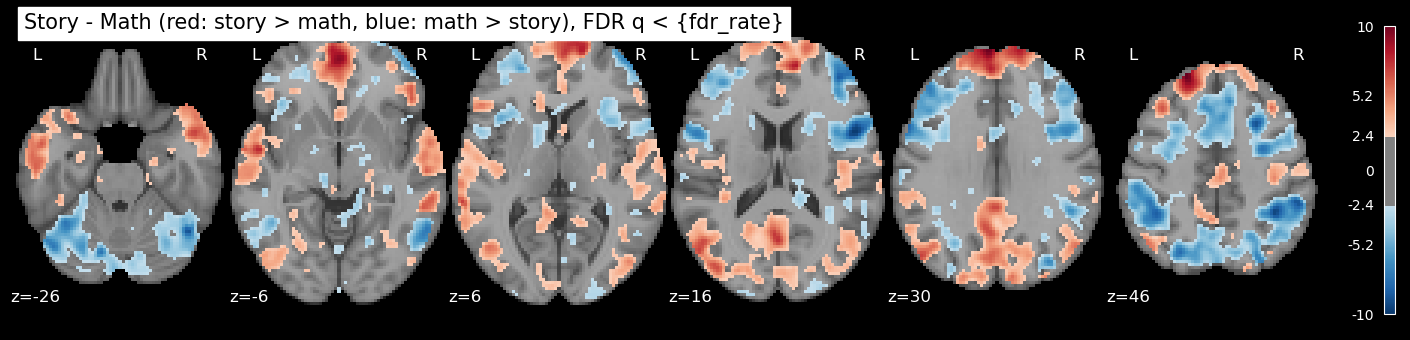

In [ ]:
clean_map, threshold = threshold_stats_img(z_story_minus_math, alpha=fdr_rate, height_control='fdr', cluster_threshold=cluster_size)

# Display number of voxels kept after thresholding
print(f"Story - Math: FDR threshold |z| > {threshold:.2f}")
print("Voxels story > math:", int((clean_map.get_fdata() > 0).sum()))
print("Voxels math > story:", int((clean_map.get_fdata() < 0).sum()))

# Print the contrast vector actually used
c_vec = (design_matrix.columns == "story").astype(int) - (design_matrix.columns == "math").astype(int)
print(pd.Series(c_vec, index=design_matrix.columns).to_string())

# Display thresholded map
plot_stat_map(
    clean_map,
    bg_img=background,
    display_mode="z",
    cut_coords=cuts,
    threshold=threshold,
    title=f"Story - Math (red: story > math, blue: math > story), FDR q < {fdr_rate}",
)

plt.show()

### e. Which regions? Harvard-Oxford atlas

The story - math map shows coloured regions. For the report we want to know where each of these regions are. We find every cluster in the map (thresholded) and its peak, the strongest voxel, look up using an atlas which brain region that peak falls in, and finally report the results in a table.

In [22]:
# Harvard-Oxford cortical and subcortical atlases
ho_cort = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
ho_sub = datasets.fetch_atlas_harvard_oxford("sub-maxprob-thr25-2mm")


[fetch_atlas_harvard_oxford] Dataset directory found: C:\Users\egeni\nilearn_data\fsl
[fetch_atlas_harvard_oxford] Dataset directory found: C:\Users\egeni\nilearn_data\fsl


In [ ]:
def atlas_label(atlas, xyz):
    """Return the name of the atlas region at MNI coordinate xyz in mm"""
    img = load_img(atlas.maps)
    data = img.get_fdata()

    # Peak table gives positions in mm (MNI coordinates) need to be converted to voxel 
    ijk = np.linalg.inv(img.affine) @ np.append(xyz, 1)
    ijk = np.round(ijk).astype(int)[:3]

    # If the coordinate falls outside the atlas image, we can't label it
    if np.any(ijk < 0) or np.any(ijk >= data.shape[:3]):
        return "outside"
 
    # Read the integer label at that voxel and turn it into region name
    label_number = int(data[ijk[0], ijk[1], ijk[2]])
    return atlas.labels[label_number]   # label 0 gives "Background"

# two_sided = True looks for both positive and negative clusters
table = get_clusters_table(z_story_minus_math, stat_threshold=threshold, cluster_threshold=cluster_size, two_sided=True)

table["Cortical (HO)"] = [atlas_label(ho_cort, r[["X", "Y", "Z"]].astype(float).values)
                          for _, r in table.iterrows()]
table["Subcortical (HO)"] = [atlas_label(ho_sub, r[["X", "Y", "Z"]].astype(float).values)
                             for _, r in table.iterrows()]

# Translate sign of peak z-value into condition direction
table["Direction"] = np.where(table["Peak Stat"].astype(float) > 0, "story > math", "math > story")
 
# Largest clusters first, keep only main peaks (e.g. 1 instead of "1a")
main = table[table["Cluster ID"].astype(str).str.isdigit()]
display(main.sort_values("Cluster Size (mm3)", ascending=False).head(20))

,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3),Cortical (HO),Subcortical (HO),Direction
4,2,-52.0,-4.0,-8.0,8.923918,132552,"Superior Temporal Gyrus, anterior division",Left Cerebral Cortex,story > math
75,73,46.0,4.0,20.0,-9.955725,123136,Background,Right Cerebral White Matter,math > story
71,72,44.0,-38.0,36.0,-10.089210,59888,Background,Right Cerebral White Matter,math > story
0,1,-20.0,46.0,46.0,10.331435,58344,Frontal Pole,Left Cerebral Cortex,story > math
8,3,62.0,-4.0,-12.0,8.762157,37360,"Middle Temporal Gyrus, anterior division",Right Cerebral Cortex,story > math
83,75,-42.0,-62.0,-54.0,-8.959226,35040,Background,Background,math > story
79,74,46.0,-58.0,-24.0,-9.157146,23504,Background,Right Cerebral Cortex,math > story
12,4,24.0,-84.0,-46.0,6.791527,5024,Background,Background,story > math
87,76,-50.0,-58.0,-10.0,-7.419956,2808,"Inferior Temporal Gyrus, temporooccipital part",Left Cerebral Cortex,math > story
16,5,-38.0,-74.0,-36.0,5.769369,2384,Background,Background,story > math


The question asks which functional networks (Yeo et al. 2011) the results fall into. The Yeo atlas assigns each cortical voxel to 1 of 7 networks (label 0 means outside of teh cortex). For each network, we count what percentage of its voxels is significant in the story - math map, separately for positive and ngeative voxels.  

In [ ]:
# We used Schaefer 2018 instead of Yeo 2011 as it was inaccessible
# It uses the same 7 networks
yeo = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\egeni\nilearn_data\schaefer_2018


,Network,story > math (% of network),math > story (% of network)
0,Visual,15.3,2.3
1,Somatomotor,3.1,0.2
2,Dorsal attention,35.3,8.4
3,Ventral attention,40.6,0.0
4,Limbic,30.0,0.2
5,Frontoparietal control,11.2,1.7
6,Default mode,6.6,0.0


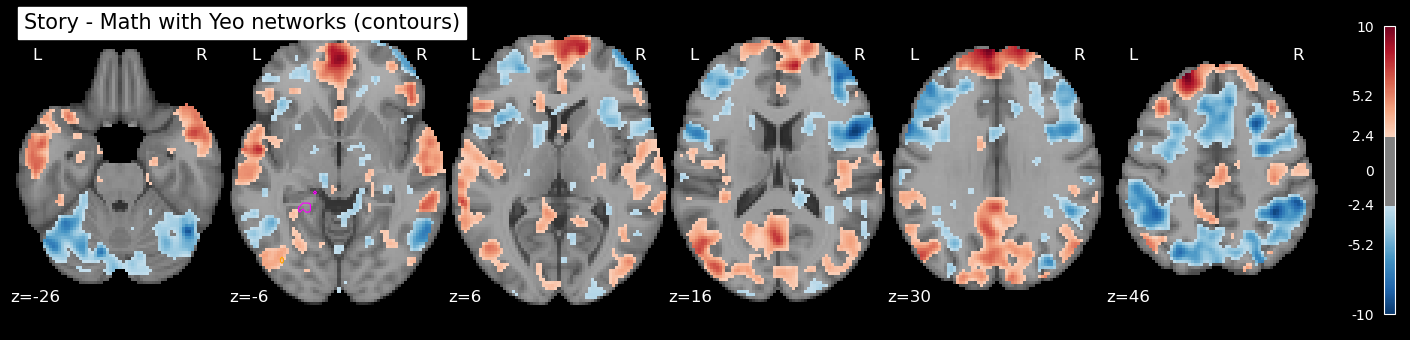

In [30]:
# Load atlas

yeo_img = load_img(yeo["thick_7"] if "thick_7" in yeo else yeo.maps) 
yeo_img = math_img("np.squeeze(img)", img=yeo_img)
yeo_img = resample_to_img(yeo_img, clean_map, interpolation="nearest")

# Network names
yeo_names = ["Visual", "Somatomotor", "Dorsal attention", "Ventral attention",
             "Limbic", "Frontoparietal control", "Default mode"]
 
yeo_data = yeo_img.get_fdata().round().astype(int)
z_data = clean_map.get_fdata()

# Count signifcant voxels inside each network
rows = []
for label, net in enumerate(yeo_names, start=1):
    in_net = yeo_data == label
    n_net = int(in_net.sum())
    pos = int(((z_data > 0) & in_net).sum())
    neg = int(((z_data < 0) & in_net).sum())
    rows.append({"Network": net,
                 "story > math (% of network)": 100 * pos / n_net,
                 "math > story (% of network)": 100 * neg / n_net})
overlap = pd.DataFrame(rows).round(1)
display(overlap)
 
# Figure for the report: Yeo networks as contours on top of the contrast map
from nilearn import plotting
display_ = plotting.plot_stat_map(clean_map, bg_img=background, display_mode="z",
                                  cut_coords=cuts, threshold=threshold,
                                  title="Story - Math with Yeo networks (contours)")
for label, colour in [(3, "lime"), (6, "orange"), (7, "magenta")]:  
    display_.add_contours(math_img(f"img == {label}", img=yeo_img),
                          levels=[0.5], colors=colour, linewidths=0.8)
    # 1 inside the network, 0 outside
plt.show()

Notes:

Main question: we choose 1 voxel and say "does the signal rise during story tasks, math tasks, or simply drift over time"


Design matrix :

Each column = one possible explanation

Each row = 1 acquired brain volume / 1 TR

math = Expected BOLD response to math tasks

drifts are included to account for changes unrelated to tasks



Initially, we had each event as 1 during the event, 0 outside of it. But as BOLD rises with a delay and falls off gradually, we need to transform it into smooth response by convolution with HRF

Bright periods = approx during the event

4 drifts: comes from nilearn function Ndrift = 2*T*fcutoff. fcutoof is 0.01 here (TODO say why?), T = Nscans * TR

--> design matrix contains possible explanatory patterns and fitting will use the measured fMRI signal to estimate the weight of every pattern at each voxel



constrasts answer "at which voxels is there evidence for a positive or negative task coefficient after accounting for the other columns"

TODO: enlever les trois premiers volumes, check threshold, check cut_coords!!!
cut_coords = 5 asks Nilearn to choose five axial slice positions. keep it constant between maps to compare them

if story_minus_math gives positive Z, it means story response > math response

threshold : decides which voxels remain visible on the map.
plot hides voxels with -thr < Z < thr and display thos with larger absolute Z-scores.
a z-score measures how strong the evidence for the constrast is, accounting for uncertainty. some voxels can exceed the threshold by chance, so the plot doesn't establish statistically significant activation.
use FDR correction at 0.05 to calculate threshold from results. it controls the expected proportion of false discoveries among the voxels declared signifcant at 5%

"math" and "story" are close to -1 as they are negatively correlated. when the predicted story response is high, math is generally low.

There is some task-drift overlap especially with drift_4, but no very strong pairwise correlations.

Drift versus drift have zero correlation (expected). 